# 51 - Visualizacao t-SNE de clusters com TF-IDF

Este notebook explora como diferentes representacoes TF-IDF afetam os agrupamentos de descricoes normalizadas de itens de notas fiscais. Ele ajusta DBSCAN no espaco TF-IDF e projeta uma amostra para tres dimensoes com t-SNE, colorindo cada ponto pelo cluster encontrado.

**Pergunta:** como mudam os grupos ao usar unigramas, unigramas e bigramas ou n-gramas de caracteres? Os grupos sao exploratorios e ainda nao representam categorias validadas. O notebook nao usa NCM nem rotulos humanos.

Execute todas as celulas em ordem, em uma sessao limpa. A primeira execucao usa a base filtrada do notebook 50 e grava imagens, coordenadas e metricas em uma pasta nova em `reports/tfidf_tsne/`.

## 1. Configuracoes

A mesma amostra de descricoes e reutilizada entre as representacoes para facilitar a comparacao. `MAX_DESCRIPTIONS` limita o custo do DBSCAN e do t-SNE; use `None` para incluir todas as descricoes, considerando o custo computacional.

Os valores de `eps` sao exploratorios e sua escala pode variar entre representacoes TF-IDF. Ajuste a grade depois de observar a quantidade de clusters e a proporcao de ruido.

O notebook salva um HTML interativo 3D para cada configuracao TF-IDF. No HTML, o seletor permite alternar entre as combinacoes de `eps` e `min_samples` do DBSCAN. Os arquivos sao autonomos e nao exigem uma dependencia nova.


In [7]:
from datetime import datetime, timezone
import html
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap
from sklearn.cluster import DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE

pd.set_option("display.max_colwidth", 120)

# Encontra a raiz do repositorio para funcionar com Jupyter iniciado em notebooks/.
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "pyproject.toml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Nao encontrei a raiz do repositorio com pyproject.toml.")

# Caminhos relativos a raiz do repositorio.
DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "2025_NCMs_filtrados_semstopwords" / "2025_NCMs_filtrados_semstopwords-202501-202512.parquet"
OUTPUT_ROOT = PROJECT_ROOT / "reports" / "tfidf_tsne"
PERIOD_LABEL = "202501-202512"  # Atualize ao trocar a base/periode.

# Amostragem fixa e compartilhada pelas configuracoes.
MAX_DESCRIPTIONS = 10_000  # Use None para todas as descricoes.
SAMPLE_RANDOM_STATE = 42

# Representacoes TF-IDF para comparar.
ANALYZER_CONFIGS = {
    "char_wb_3_5": ("char_wb", (3, 5)),
    "char_wb_4_8": ("char_wb", (4, 8)),
    "char_wb_5_10": ("char_wb", (5, 10)),
    "char_wb_1_15": ("char_wb", (1, 15)),
    "word_1_2": ("word", (1, 2)),
    "word_1_3": ("word", (1, 3)),
    "word_1_4": ("word", (1, 4)),
    "word_1_5": ("word", (1, 5)),
    "word_2_4": ("word", (2, 4)),
    "word_2_5": ("word", (2, 5)),
}
MIN_DF = 5
MAX_FEATURES = 30_000
TFIDF_CONFIGS = [
    {
        "name": f"{name}_df{MIN_DF}",
        "analyzer": analyzer,
        "ngram_range": ngram_range,
        "min_df": MIN_DF,
        "max_features": MAX_FEATURES,
    }
    for name, (analyzer, ngram_range) in ANALYZER_CONFIGS.items()
]

# Grade exploratoria do DBSCAN (distancia cosseno no espaco TF-IDF).
EPS_VALUES = [0.03, 0.1]
MIN_SAMPLES_VALUES = [3, 10]
DBSCAN_N_JOBS = 1

# Parametros do t-SNE. O SVD reduz a matriz esparsa antes da projecao.
SVD_COMPONENTS = 50
TSNE_PERPLEXITY = 30
TSNE_MAX_ITER = 1_000
TSNE_RANDOM_STATE = 42
TSNE_POINT_SIZE = 9

## 2. Funcoes da analise

O TF-IDF e ajustado uma vez por representacao. O DBSCAN opera sobre a matriz TF-IDF esparsa; o t-SNE recebe uma projecao intermediaria de SVD com no maximo `SVD_COMPONENTS` dimensoes. A projecao e calculada uma vez por representacao e reutilizada nos graficos de diferentes parametros DBSCAN.

O ruido do DBSCAN (`cluster = -1`) aparece em cinza. As outras cores representam os grupos encontrados. A amostra t-SNE e a amostra usada pelo DBSCAN sao as mesmas.

In [8]:
def load_modeling_items(path):
    if not path.is_file():
        raise FileNotFoundError(f"Arquivo Parquet nao encontrado: {path}")

    raw_items = pd.read_parquet(path)
    required_columns = {"descricao_normalizada", "frequencia"}
    missing_columns = required_columns.difference(raw_items.columns)
    if missing_columns:
        raise ValueError(f"Colunas obrigatorias ausentes: {sorted(missing_columns)}")

    items = raw_items[["descricao_normalizada", "frequencia"]].copy()
    items["descricao_normalizada"] = items["descricao_normalizada"].astype("string").str.strip()
    items["frequencia"] = pd.to_numeric(items["frequencia"], errors="raise")
    items = items.dropna(subset=["descricao_normalizada", "frequencia"])
    items = items.loc[items["descricao_normalizada"].ne("") & items["frequencia"].ge(1)]
    items = (
        items.groupby("descricao_normalizada", as_index=False, sort=False)["frequencia"]
        .sum()
        .sort_values("descricao_normalizada")
        .reset_index(drop=True)
    )
    items["frequencia"] = items["frequencia"].astype("int64")
    return items


def project_with_tsne(matrix, perplexity, max_components, random_state):
    if matrix.shape[0] < 3:
        raise ValueError("O t-SNE requer pelo menos tres descricoes.")
    if matrix.shape[1] < 3:
        raise ValueError("Sao necessarias ao menos tres features TF-IDF para o SVD.")

    component_count = min(max_components, matrix.shape[1] - 1)
    reduced = TruncatedSVD(n_components=component_count, random_state=random_state).fit_transform(matrix)
    effective_perplexity = min(perplexity, matrix.shape[0] - 1)
    coordinates = TSNE(
        n_components=3,
        perplexity=effective_perplexity,
        max_iter=TSNE_MAX_ITER,
        init="pca",
        learning_rate="auto",
        random_state=random_state,
    ).fit_transform(reduced)
    return coordinates, component_count, effective_perplexity


def plot_clusters(coordinates, labels, title, output_path):
    fig, axis = plt.subplots(figsize=(12, 8))
    noise_mask = labels == -1
    cluster_ids = np.unique(labels[~noise_mask])
    palette = plt.get_cmap("tab20").colors

    if noise_mask.any():
        axis.scatter(
            coordinates[noise_mask, 0], coordinates[noise_mask, 1],
            c="#c7c7c7", s=TSNE_POINT_SIZE, alpha=0.45,
            linewidths=0, label="Ruido (-1)", rasterized=True,
        )
    if cluster_ids.size:
        colors = [palette[index % len(palette)] for index in range(len(cluster_ids))]
        color_map = ListedColormap(colors)
        cluster_codes = np.searchsorted(cluster_ids, labels[~noise_mask])
        axis.scatter(
            coordinates[~noise_mask, 0], coordinates[~noise_mask, 1],
            c=cluster_codes, cmap=color_map, vmin=-0.5,
            vmax=len(cluster_ids) - 0.5, s=TSNE_POINT_SIZE,
            alpha=0.8, linewidths=0, rasterized=True,
        )

    noise_count = int(noise_mask.sum())
    axis.set_title(
        f"t-SNE: {title}\n{len(cluster_ids):,} clusters; "
        f"{len(labels):,} descricoes; {noise_count:,} em ruido"
    )
    axis.set_xlabel("t-SNE 1")
    axis.set_ylabel("t-SNE 2")
    axis.text(0.01, 0.01, "Ruido em cinza; cores representam clusters DBSCAN.",
              transform=axis.transAxes, fontsize=9, color="#444444")
    fig.tight_layout()
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_interactive_tsne_html(coordinates, items, cluster_options, title, output_path):
    # Exporta coordenadas e agrupamentos para um HTML local e interativo.
    payload = {
        "title": title,
        "points": [
            {"x": float(point[0]), "y": float(point[1]), "z": float(point[2]),
             "description": str(description), "frequency": int(frequency)}
            for point, description, frequency in zip(
                coordinates, items["descricao_normalizada"], items["frequencia"]
            )
        ],
        "configurations": cluster_options,
    }
    payload_json = json.dumps(payload, ensure_ascii=False).replace("<", "\\u003c")
    document = r'''<!doctype html>
<html lang="pt-BR"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITLE__</title>
<style>
body{margin:0;color:#202124;font:14px system-ui,sans-serif}header{display:flex;flex-wrap:wrap;align-items:center;gap:12px;padding:12px 18px}h1{margin:0 18px 0 0;font-size:18px}select{max-width:min(680px,90vw);padding:7px}#summary{color:#555}#chart{display:block;width:100vw;height:calc(100vh - 80px);cursor:grab}#chart:active{cursor:grabbing}.help{padding:0 18px 8px;color:#555}#tooltip{position:fixed;display:none;max-width:360px;padding:8px 10px;color:white;background:#222e;border-radius:5px;pointer-events:none}
</style></head><body>
<header><h1 id="title"></h1><label for="configuration">Configuracao DBSCAN:</label><select id="configuration"></select><span id="summary"></span></header>
<div class="help">Arraste para girar; use a roda do mouse para aproximar. Passe sobre um ponto para ver descricao e frequencia.</div>
<canvas id="chart"></canvas><div id="tooltip"></div>
<script id="chart-data" type="application/json">__PAYLOAD__</script><script>
const data=JSON.parse(document.getElementById('chart-data').textContent);
document.getElementById('title').textContent=data.title;
const selector=document.getElementById('configuration'),summary=document.getElementById('summary');
const canvas=document.getElementById('chart'),ctx=canvas.getContext('2d'),tooltip=document.getElementById('tooltip');
let active=0,yaw=.55,pitch=.35,zoom=1,drag=null,projected=[];
const palette=['#3366cc','#dc3912','#ff9900','#109618','#990099','#0099c6','#dd4477','#66aa00','#b82e2e','#316395','#994499','#22aa99','#aaaa11','#6633cc','#e67300','#8b0707','#651067','#329262','#5574a6','#3b3eac'];
data.configurations.forEach((item,index)=>{const option=document.createElement('option');option.value=index;option.textContent=item.name;selector.appendChild(option)});
function colorFor(label){return label===-1?'#b8b8b8':palette[((label%palette.length)+palette.length)%palette.length]}
function resize(){const ratio=window.devicePixelRatio||1;canvas.width=Math.round(canvas.clientWidth*ratio);canvas.height=Math.round(canvas.clientHeight*ratio);ctx.setTransform(ratio,0,0,ratio,0,0);draw()}
function draw(){const width=canvas.clientWidth,height=canvas.clientHeight,points=data.points;ctx.clearRect(0,0,width,height);if(!points.length)return;
const labels=data.configurations[active].labels,cx=points.reduce((s,p)=>s+p.x,0)/points.length,cy=points.reduce((s,p)=>s+p.y,0)/points.length,cz=points.reduce((s,p)=>s+p.z,0)/points.length;
const radius=Math.max(...points.map(p=>Math.hypot(p.x-cx,p.y-cy,p.z-cz)))||1,scale=Math.min(width,height)*.39*zoom,cyaw=Math.cos(yaw),syaw=Math.sin(yaw),cp=Math.cos(pitch),sp=Math.sin(pitch);
projected=points.map((p,i)=>{const x=(p.x-cx)/radius,y=(p.y-cy)/radius,z=(p.z-cz)/radius,rx=x*cyaw-z*syaw,rz=x*syaw+z*cyaw,ry=y*cp-rz*sp,depth=y*sp+rz*cp,perspective=2.8/(2.8-depth*.55);return{x:width/2+rx*scale*perspective,y:height/2-ry*scale*perspective,depth,label:labels[i],index:i}}).sort((a,b)=>a.depth-b.depth);
for(const p of projected){ctx.globalAlpha=p.label===-1?.48:.82;ctx.fillStyle=colorFor(p.label);ctx.beginPath();ctx.arc(p.x,p.y,p.label===-1?2.4:3.1,0,Math.PI*2);ctx.fill()}ctx.globalAlpha=1;
const config=data.configurations[active];summary.textContent=`${config.cluster_count} clusters · ${config.noise_count} ruidosos · ${points.length} descricoes`}
selector.addEventListener('change',()=>{active=Number(selector.value);draw()});
canvas.addEventListener('pointerdown',e=>{drag=[e.clientX,e.clientY];canvas.setPointerCapture(e.pointerId)});
canvas.addEventListener('pointermove',e=>{if(drag){yaw+=(e.clientX-drag[0])*.008;pitch=Math.max(-1.45,Math.min(1.45,pitch+(e.clientY-drag[1])*.008));drag=[e.clientX,e.clientY];draw();return}
const rect=canvas.getBoundingClientRect(),x=e.clientX-rect.left,y=e.clientY-rect.top;let nearest=null,distance=100;for(const p of projected){const d=Math.hypot(p.x-x,p.y-y);if(d<distance){distance=d;nearest=p}}
if(nearest&&distance<10){const p=data.points[nearest.index];tooltip.textContent=`${p.description} · frequencia: ${p.frequency} · cluster: ${nearest.label}`;tooltip.style.display='block';tooltip.style.left=`${e.clientX+12}px`;tooltip.style.top=`${e.clientY+12}px`}else tooltip.style.display='none'});
canvas.addEventListener('pointerup',()=>{drag=null});canvas.addEventListener('wheel',e=>{e.preventDefault();zoom=Math.max(.3,Math.min(5,zoom*(e.deltaY<0?1.1:.9)));draw()},{passive:false});window.addEventListener('resize',resize);selector.value='0';resize();
</script></body></html>'''
    document = document.replace("__TITLE__", html.escape(title)).replace("__PAYLOAD__", payload_json)
    output_path.write_text(document, encoding="utf-8")


## 3. Carregar e amostrar dados

Origem: Parquet processado e filtrado usado na analise TF-IDF do notebook 50. A unidade de analise e uma descricao normalizada unica; `frequencia` e preservada para contextualizar o volume, mas nao pondera o DBSCAN. O conjunto e ordenado e amostrado com semente fixa para que todas as representacoes sejam comparadas nas mesmas descricoes.

In [9]:
base_items = load_modeling_items(DATASET_PATH)
if base_items.empty:
    raise ValueError("Nao ha descricoes validas para analisar.")

if MAX_DESCRIPTIONS is not None and len(base_items) > MAX_DESCRIPTIONS:
    sampled_items = (
        base_items.sample(n=MAX_DESCRIPTIONS, random_state=SAMPLE_RANDOM_STATE)
        .sort_values("descricao_normalizada")
        .reset_index(drop=True)
    )
else:
    sampled_items = base_items.reset_index(drop=True)

print(f"Descricoes unicas disponiveis: {len(base_items):,}")
print(f"Descricoes usadas na analise: {len(sampled_items):,}")
print(f"Frequencia representada pela amostra: {sampled_items['frequencia'].sum():,}")
display(sampled_items.head())

Descricoes unicas disponiveis: 146,999
Descricoes usadas na analise: 10,000
Frequencia representada pela amostra: 60,396


,descricao_normalizada,frequencia
0,0 25kg adesivo epoxi massa bi componente com base resina epoxi poliamida cargas minerais para reparos,1
1,00007 detergente composicao tensoativo anionico biodegradavel ph 6 5 7 5 c aroma neutro aspecto fisico l,1
2,0001 petit four,7
3,00054 bolo alimenticio sabor maracuja tipo torta confeitada peso 2 kg caracteristicas adicionais com 30 cm d,2
4,0009 saco plastico ksf 1050x2500,1


## 4. Vetorizar, clusterizar e projetar

Para cada representacao, o notebook ajusta TF-IDF, roda DBSCAN para cada combinacao de `eps` e `min_samples` e gera um PNG colorido pela atribuicao correspondente e, ao final de cada representacao, um HTML 3D com seletor para alternar entre as configuracoes DBSCAN. O resumo registra o numero de clusters, a fracao de ruido e o tamanho do maior cluster para ajudar a selecionar configuracoes para inspecao.

Descricoes sem termos sobreviventes ao TF-IDF permanecem na amostra. A quantidade e a proporcao de vetores zerados sao registradas em `metrics.csv` para cada configuracao.


Vetorizando char_wb_3_5_df5...
  Matriz: 10,000 descricoes x 15,908 features; 0 vetores zerados


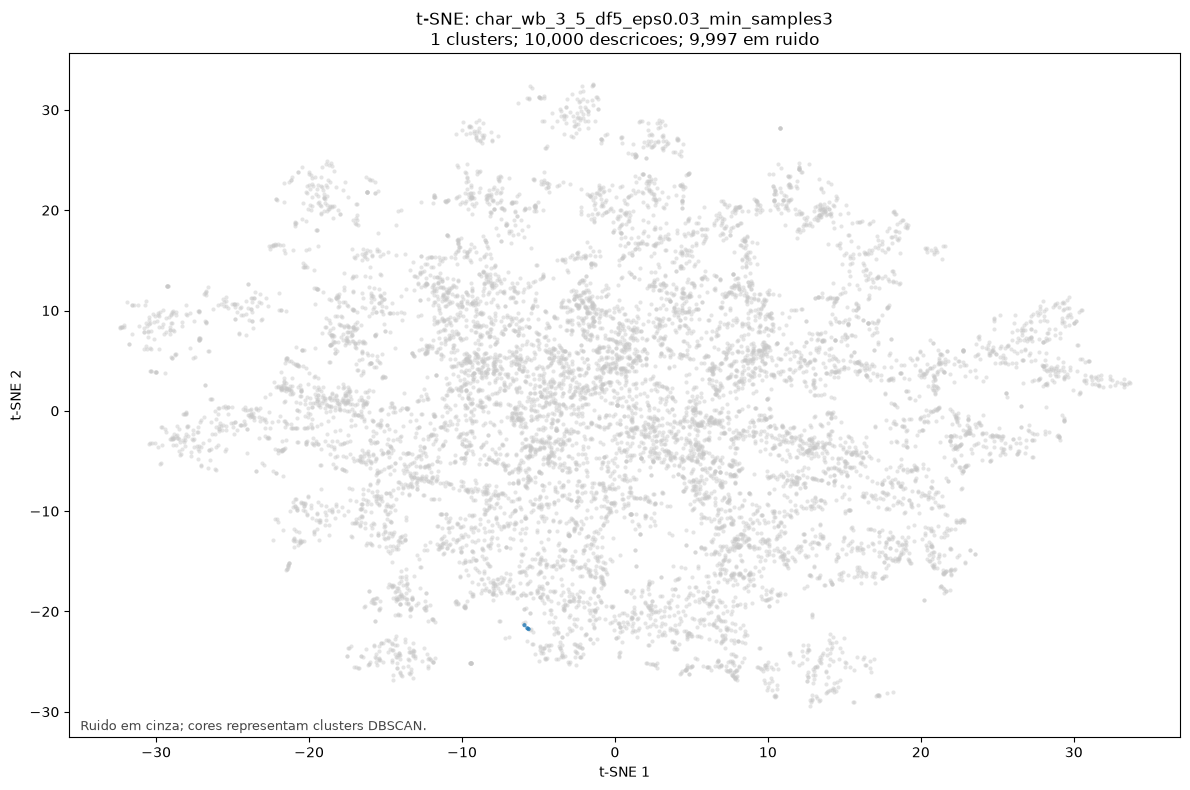

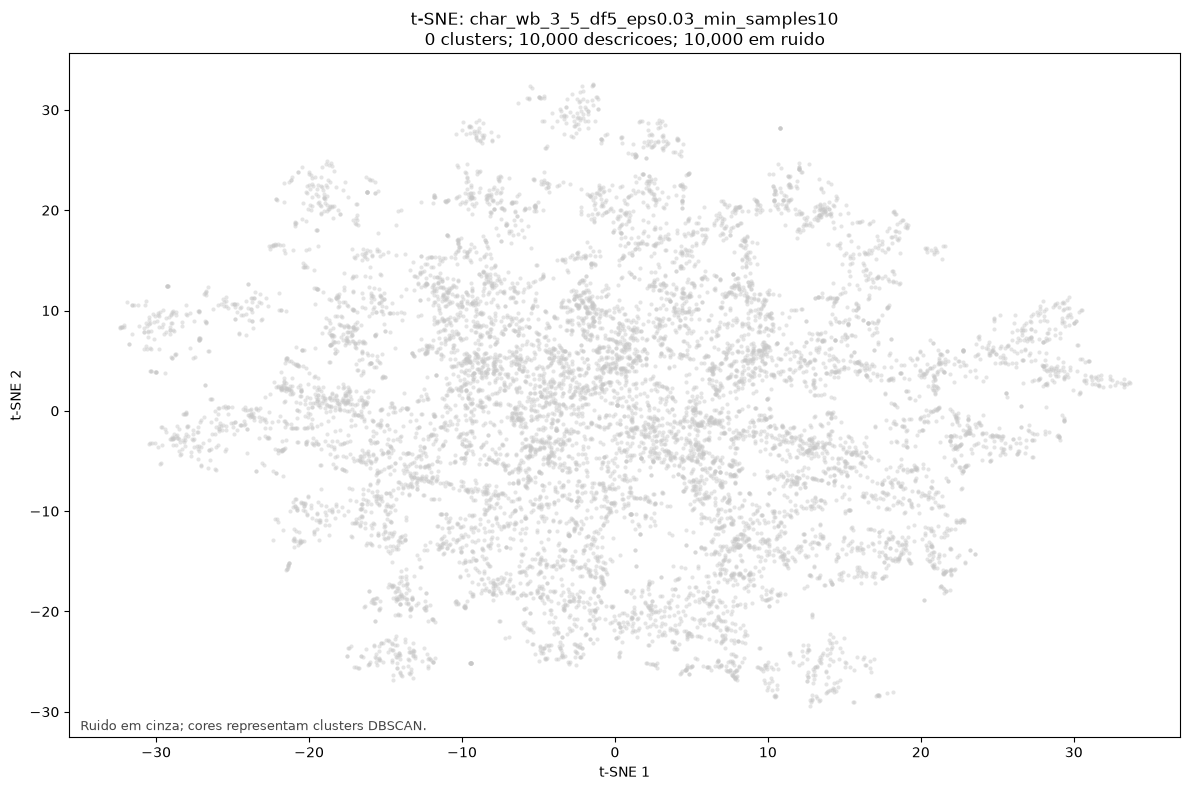

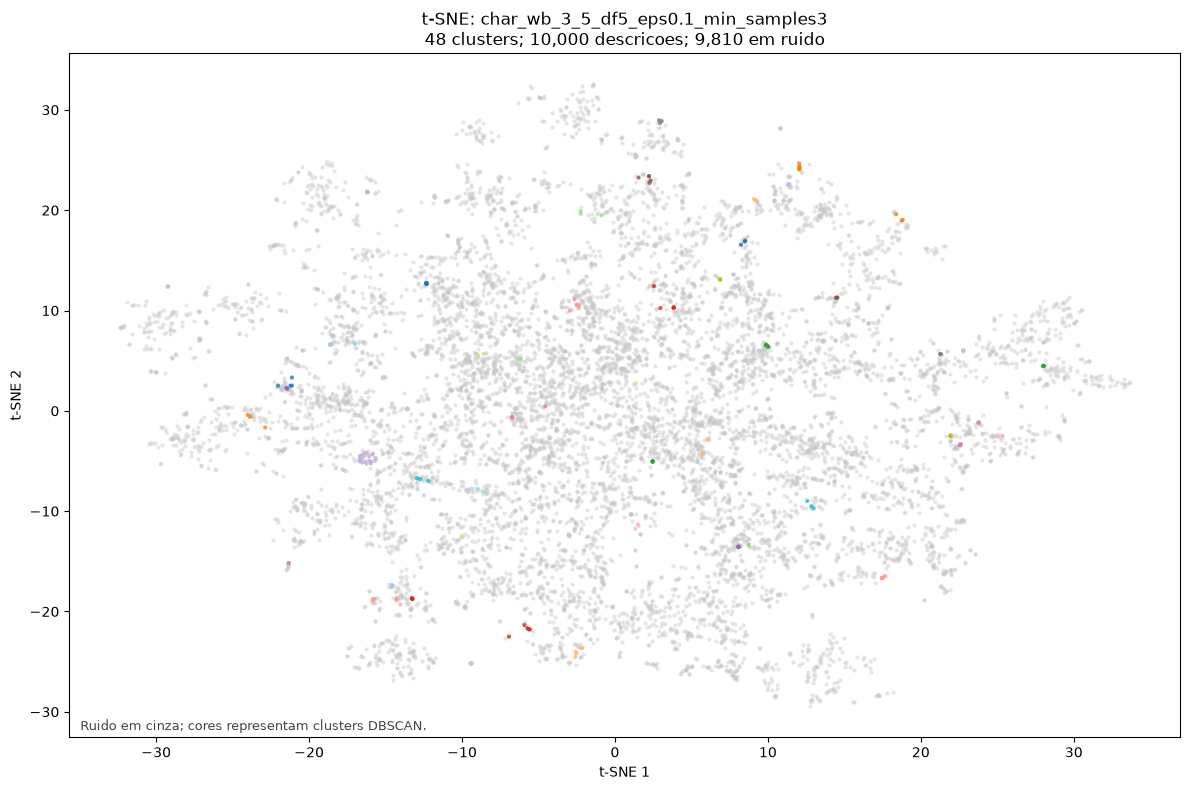

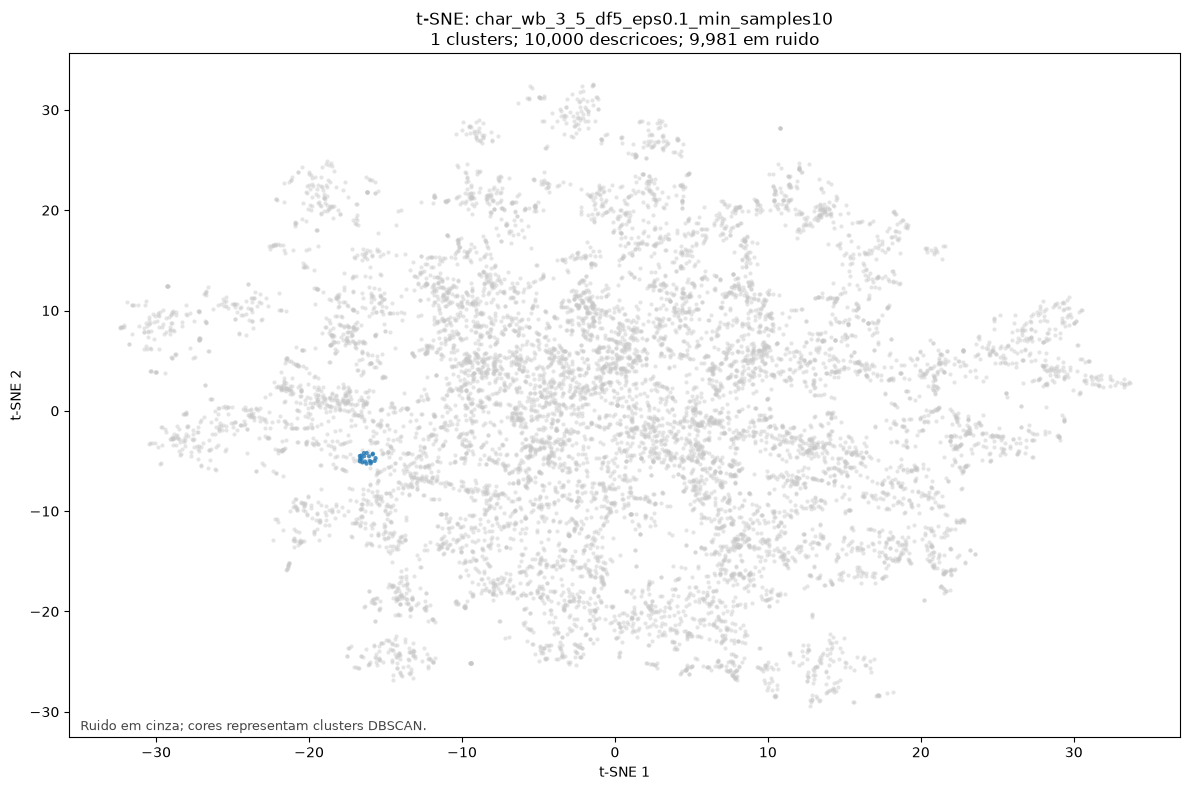

Vetorizando char_wb_4_8_df5...
  Matriz: 10,000 descricoes x 23,073 features; 0 vetores zerados


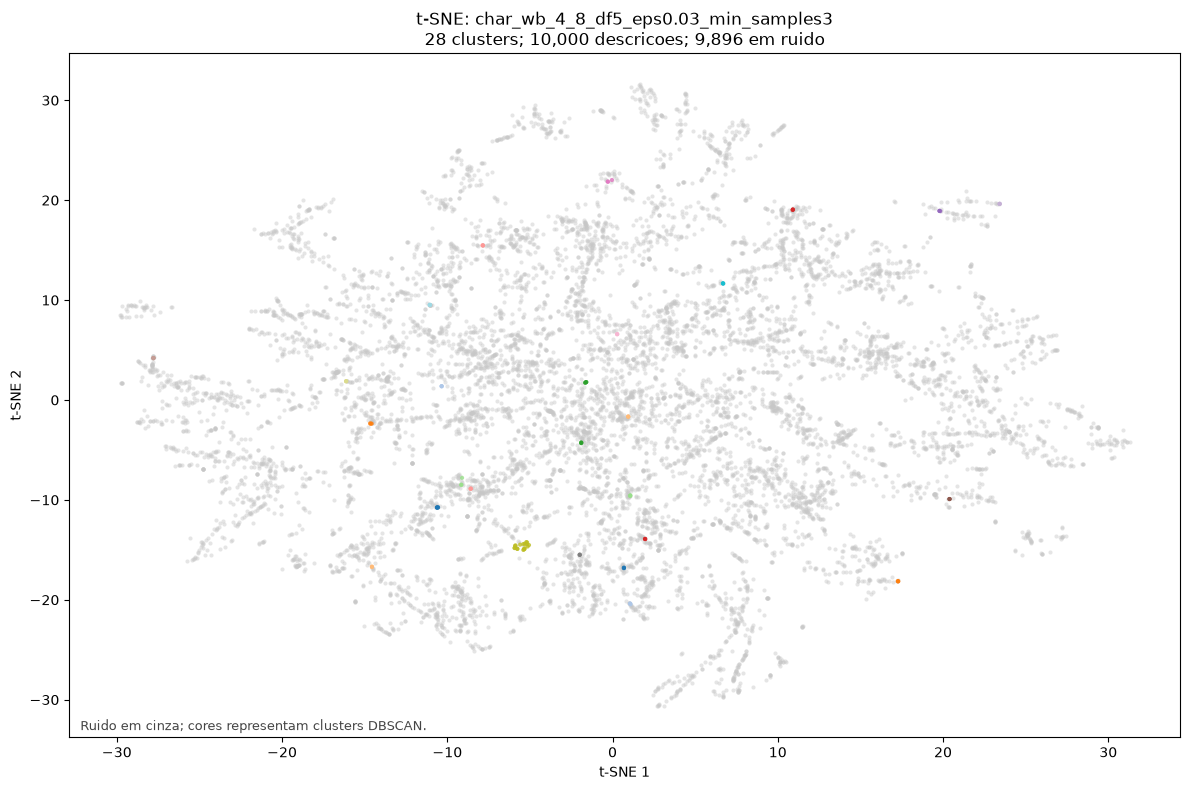

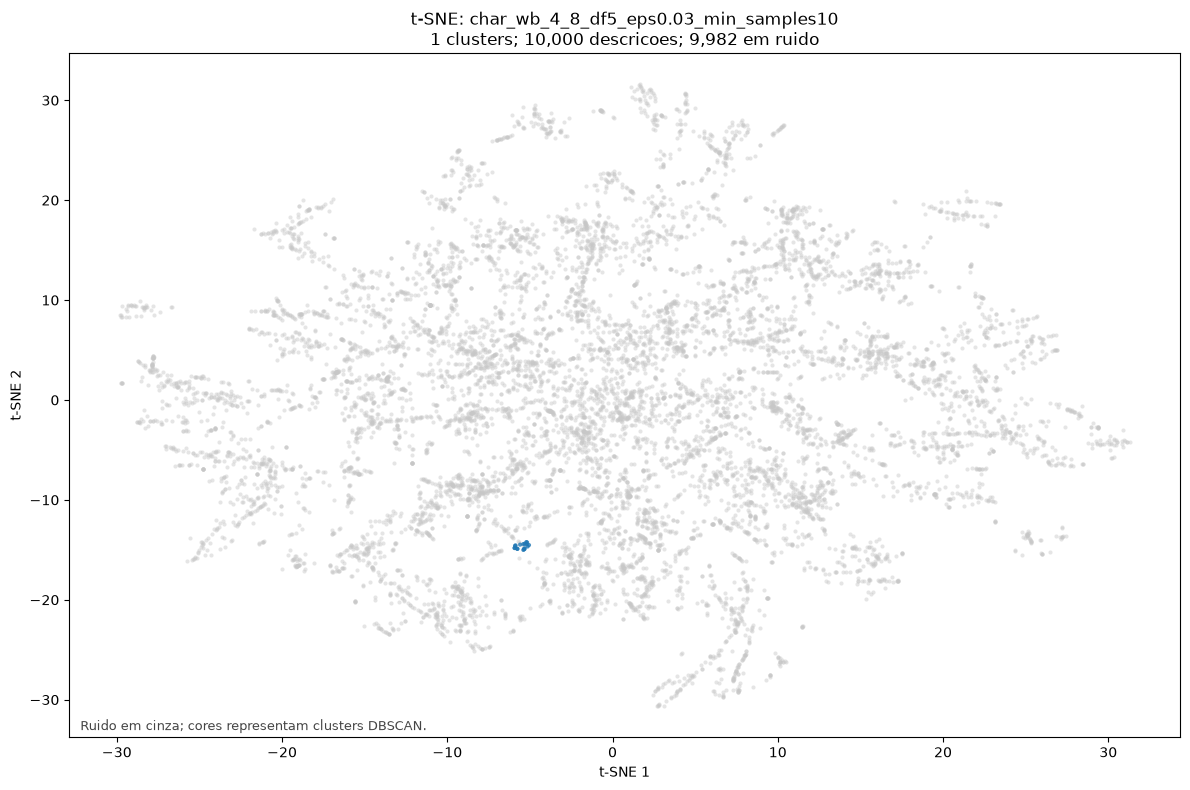

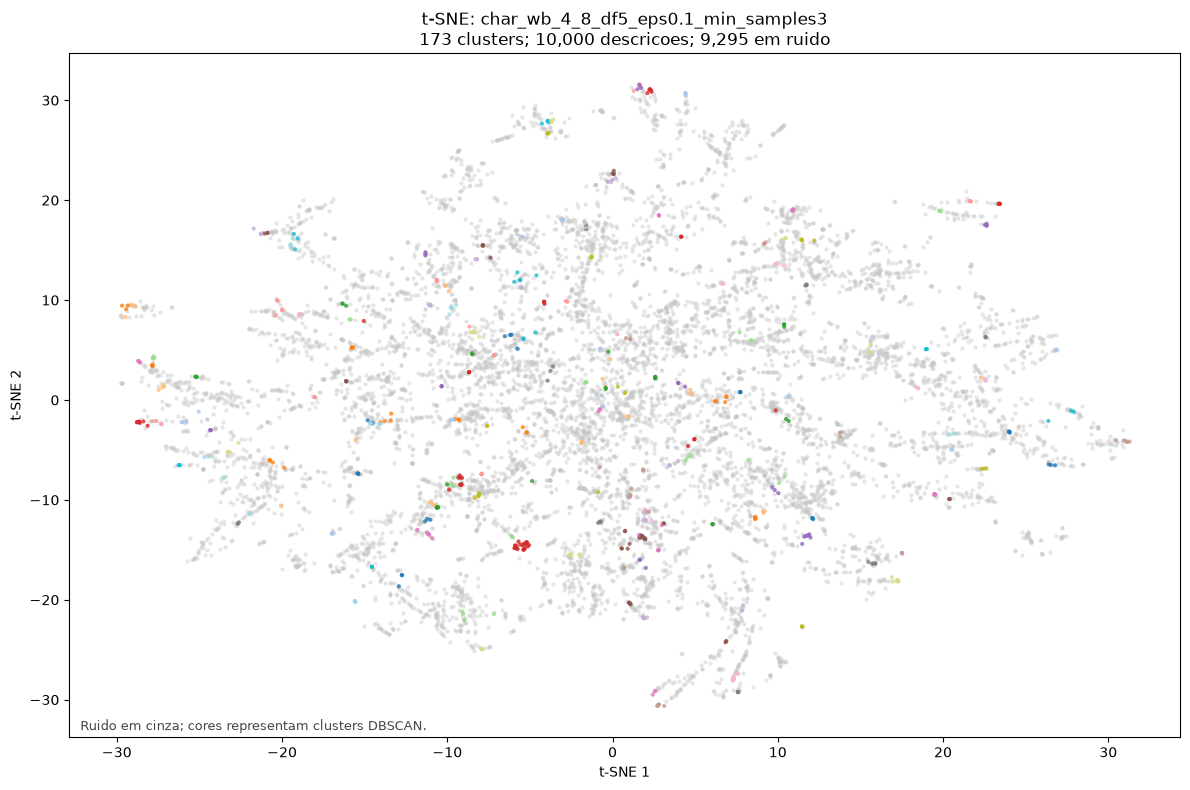

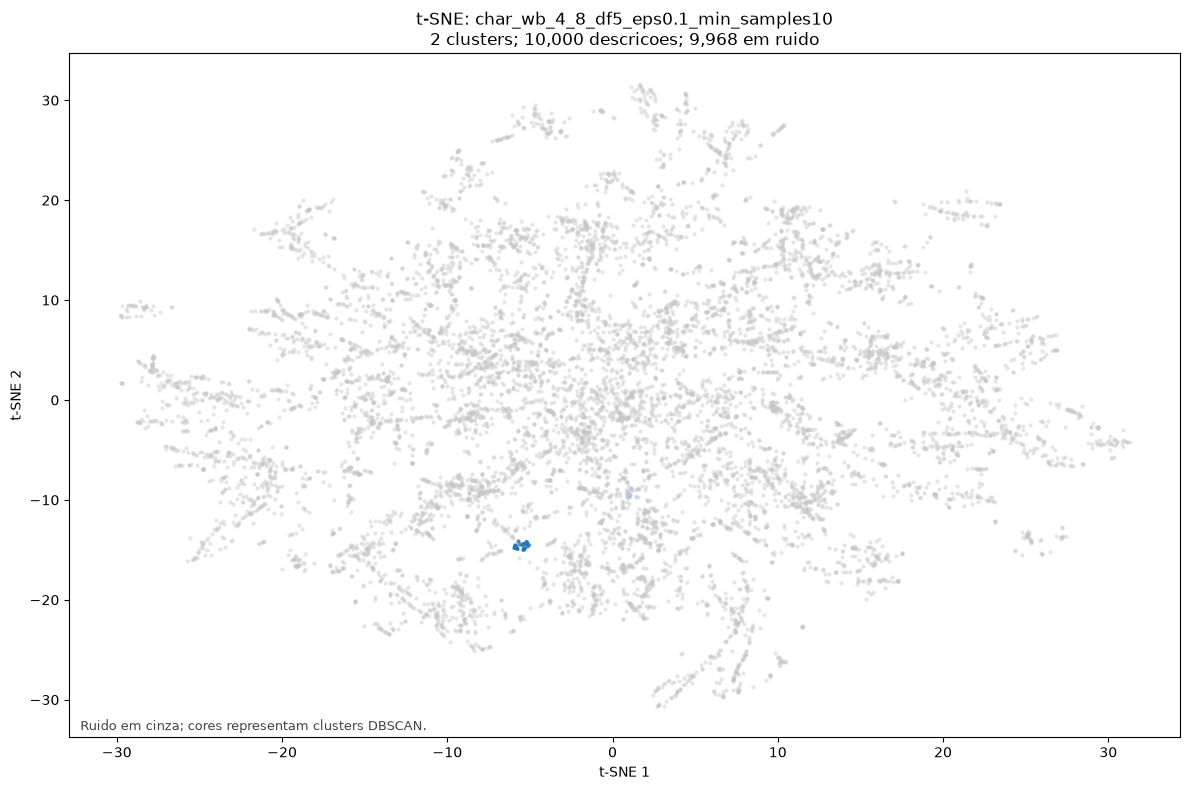

Vetorizando char_wb_5_10_df5...
  Matriz: 10,000 descricoes x 19,333 features; 19 vetores zerados
  Aviso: 19 descricoes ficaram sem features nesta representacao.


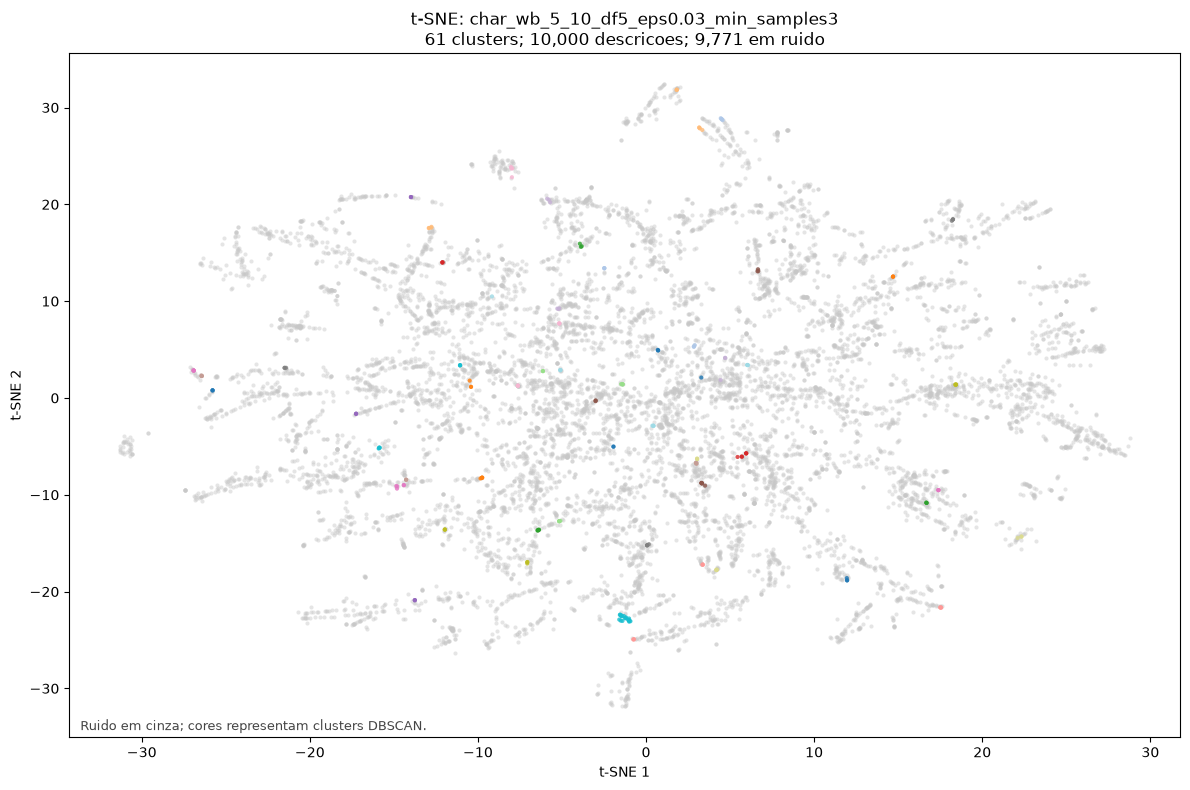

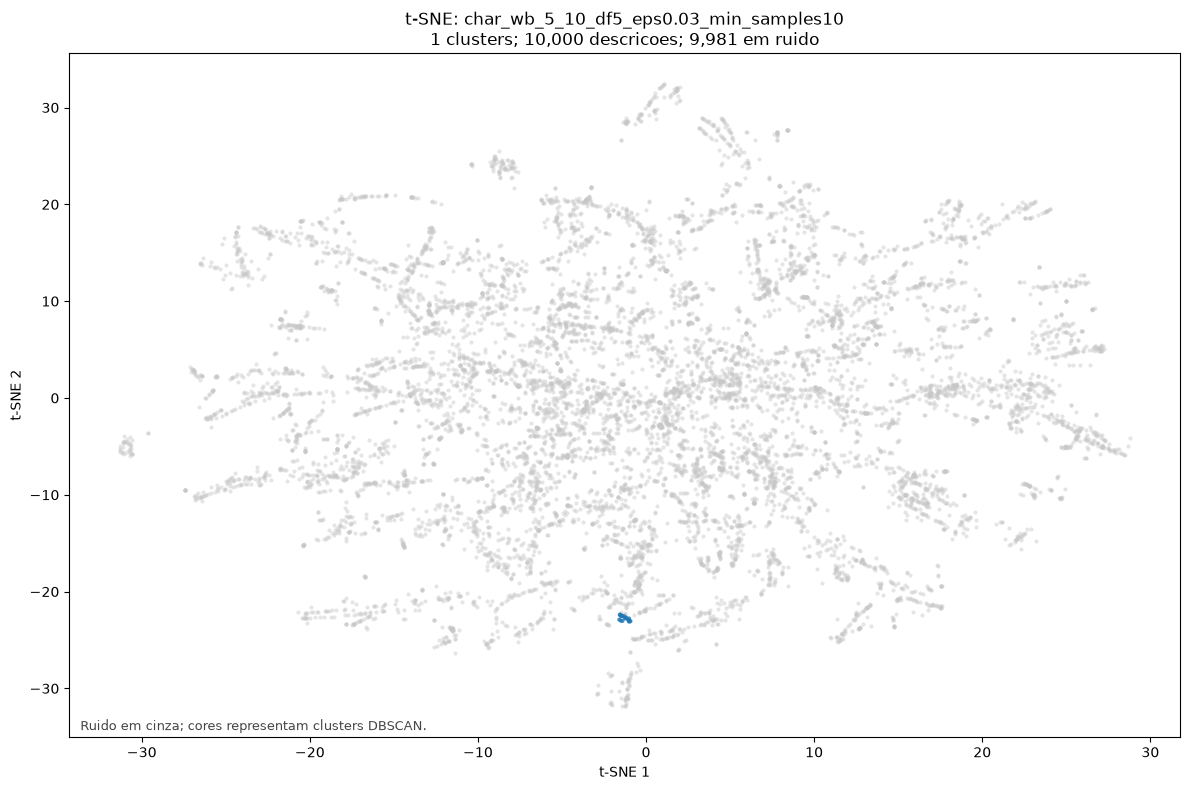

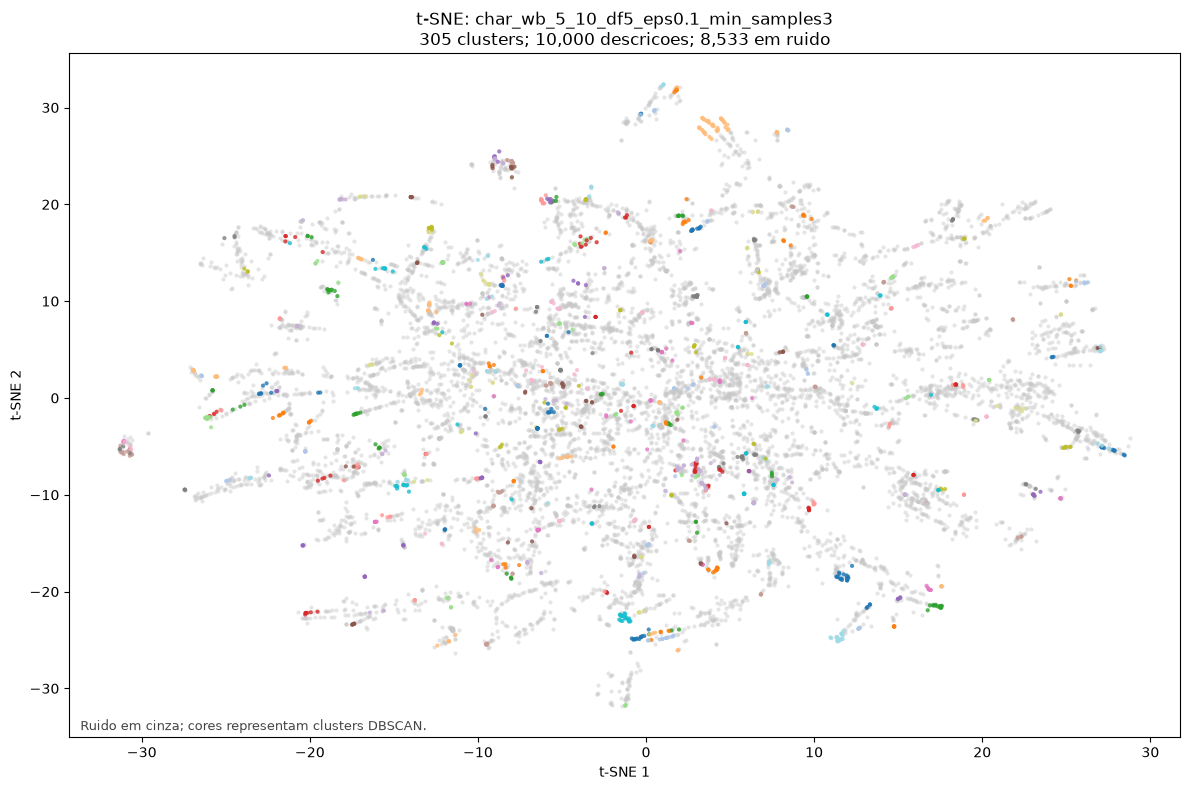

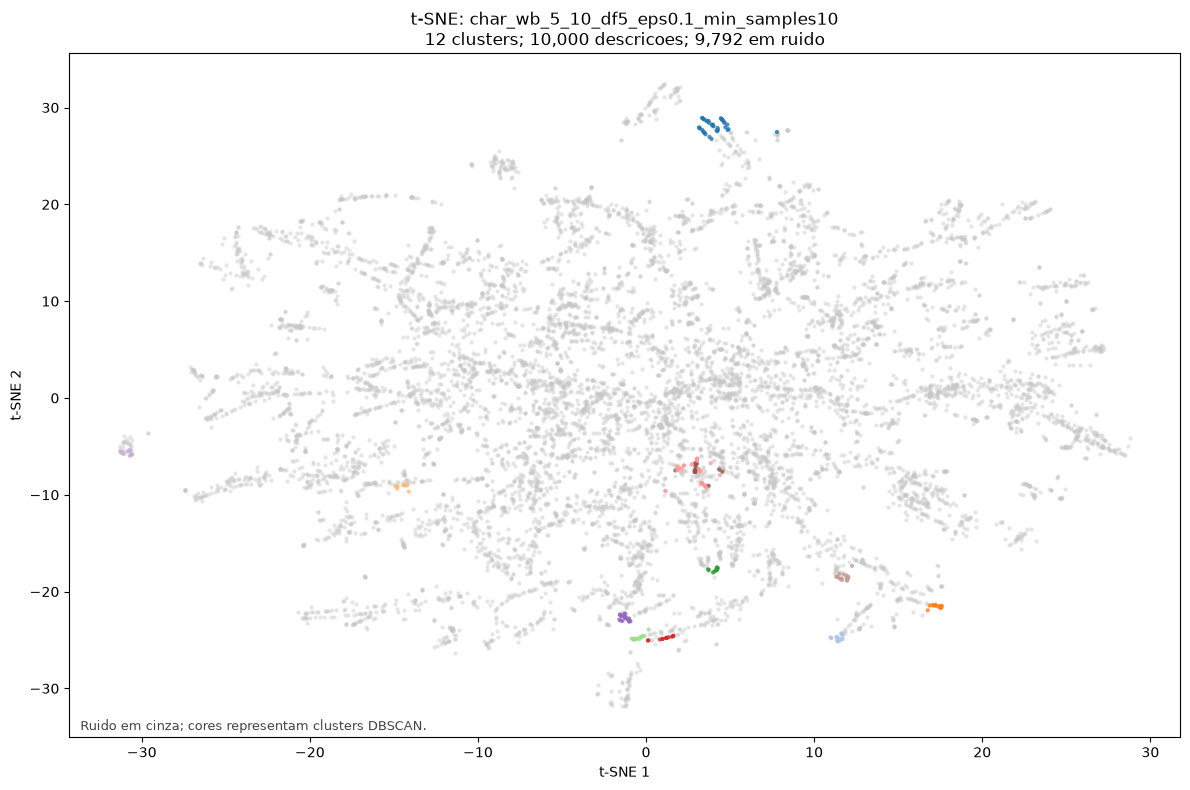

Vetorizando char_wb_1_15_df5...
  Matriz: 10,000 descricoes x 30,000 features; 0 vetores zerados


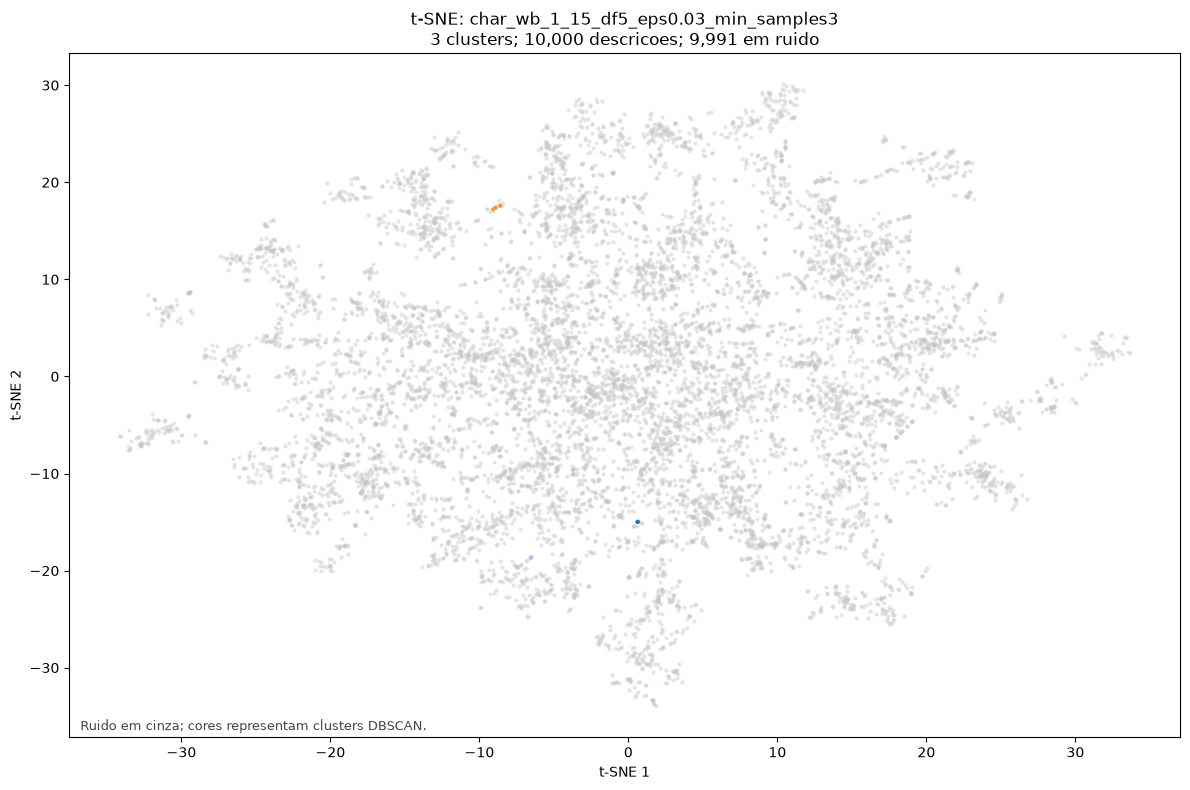

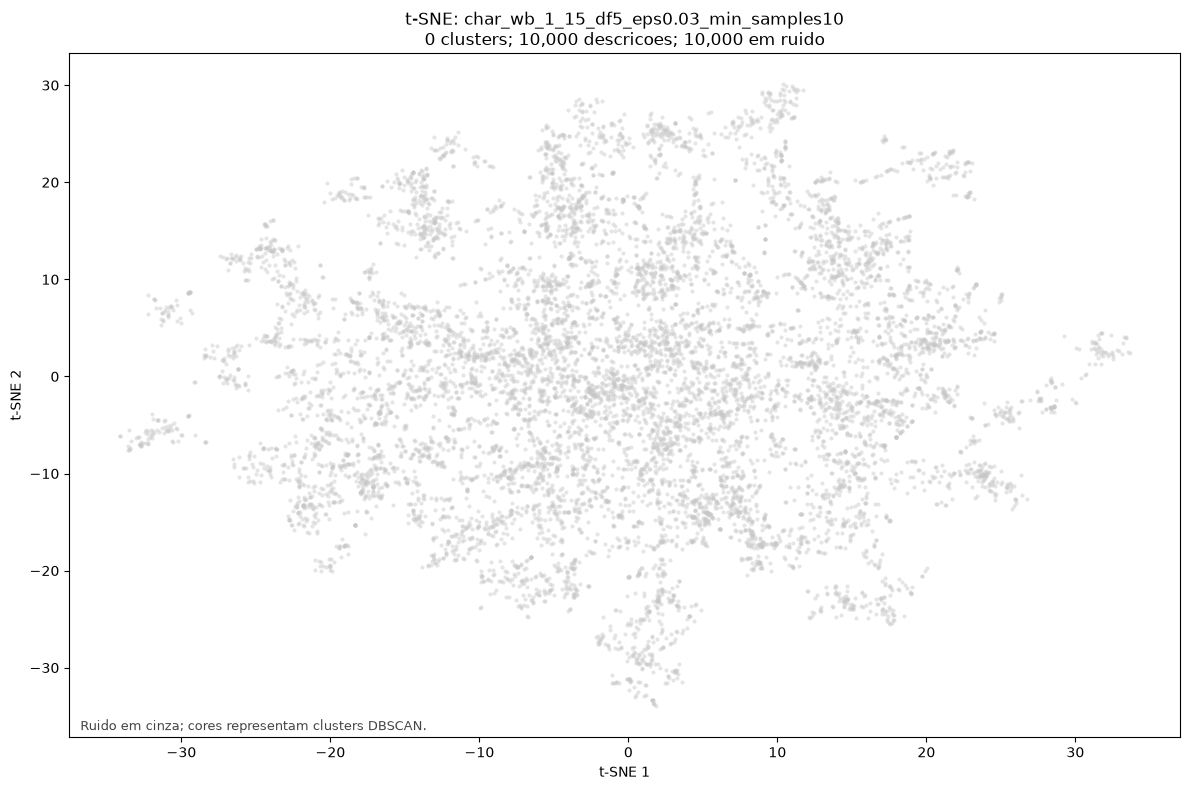

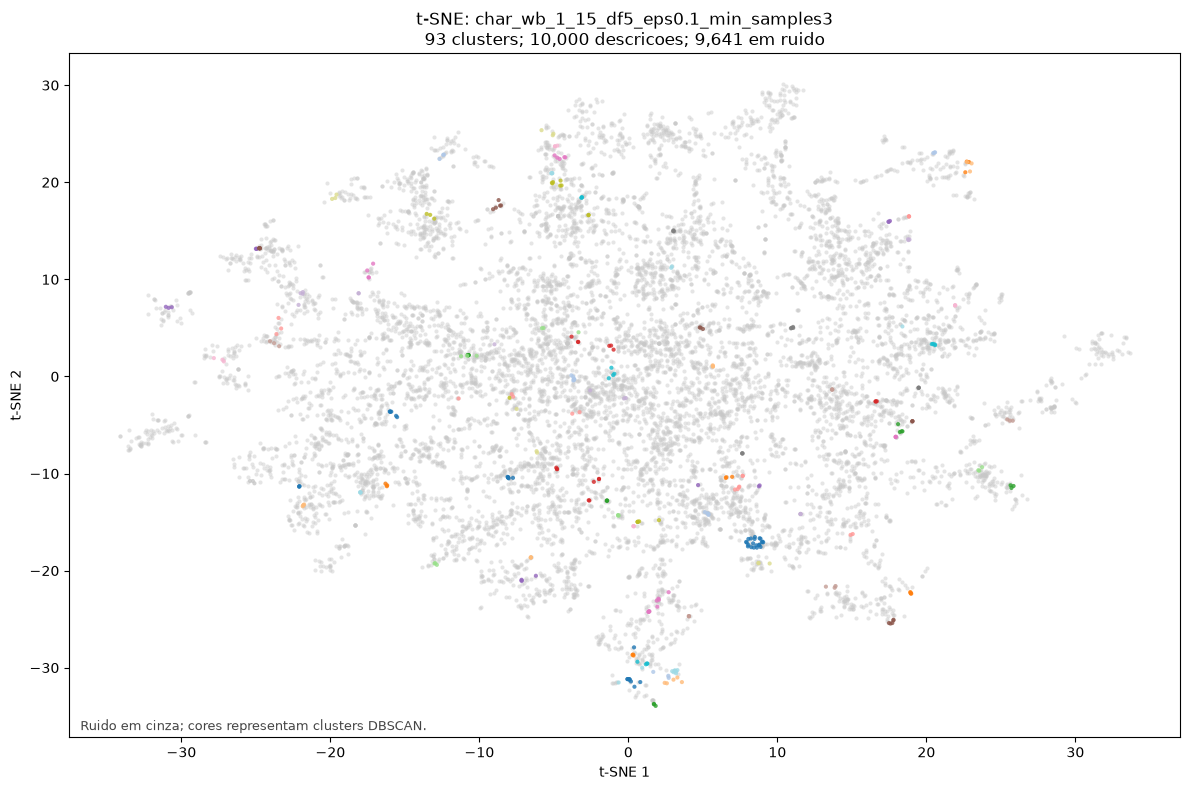

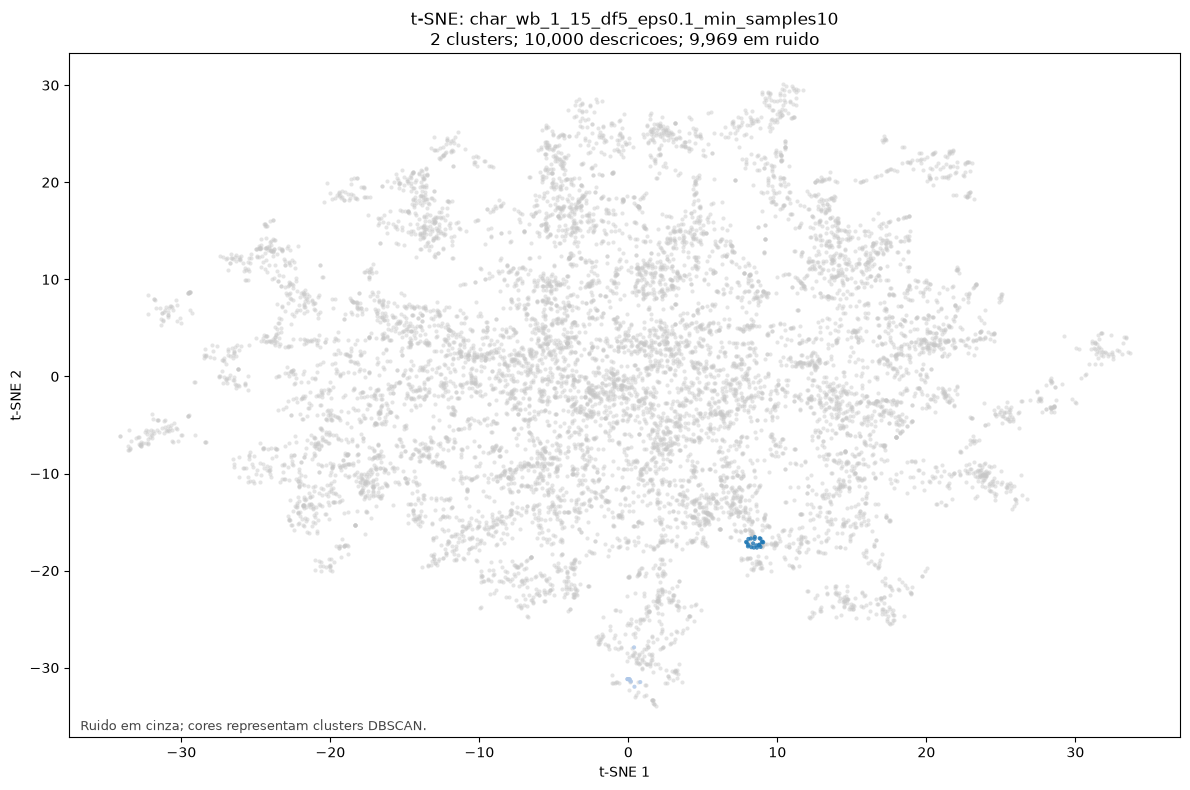

Vetorizando word_1_2_df5...
  Matriz: 10,000 descricoes x 2,675 features; 162 vetores zerados
  Aviso: 162 descricoes ficaram sem features nesta representacao.


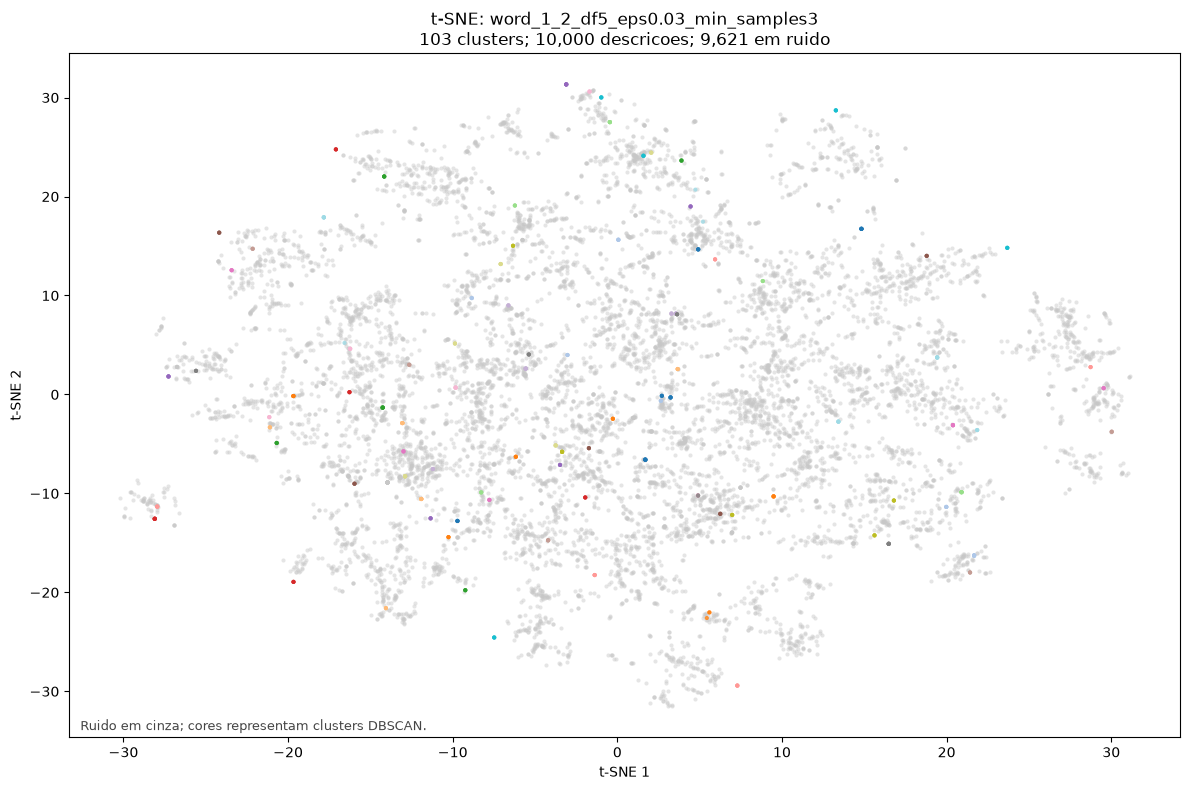

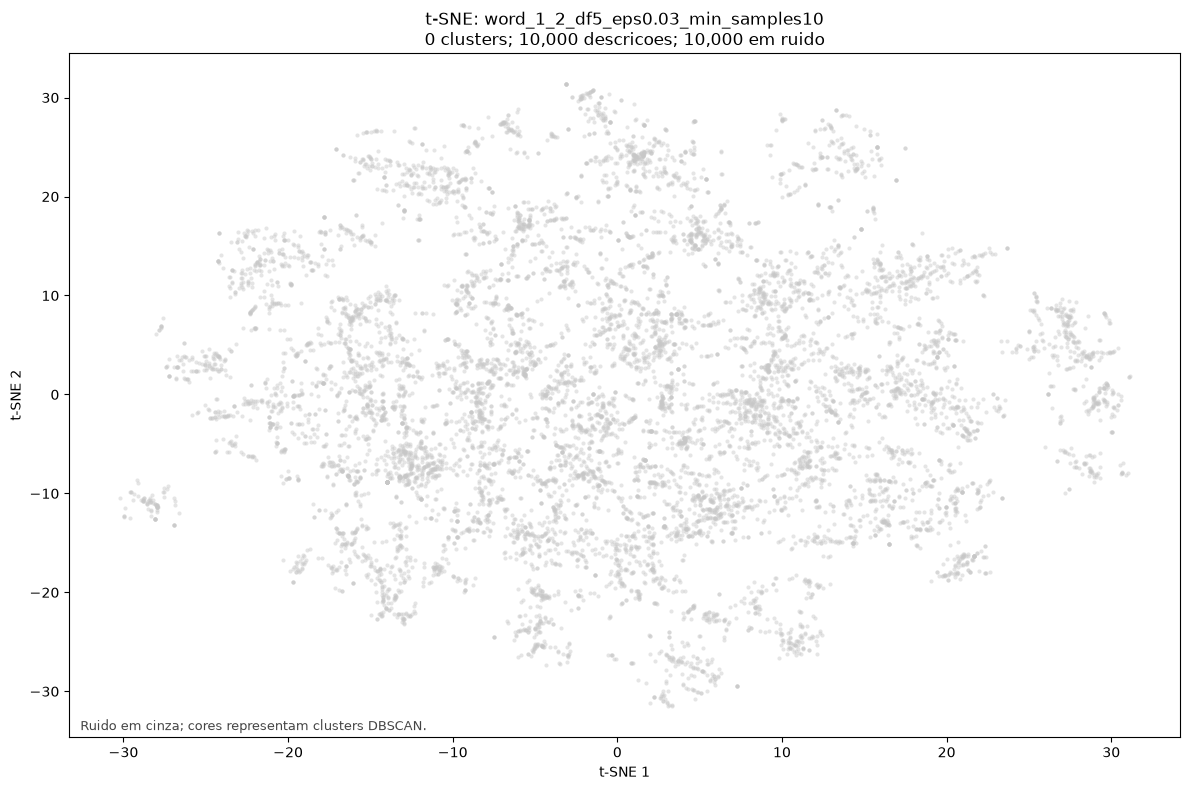

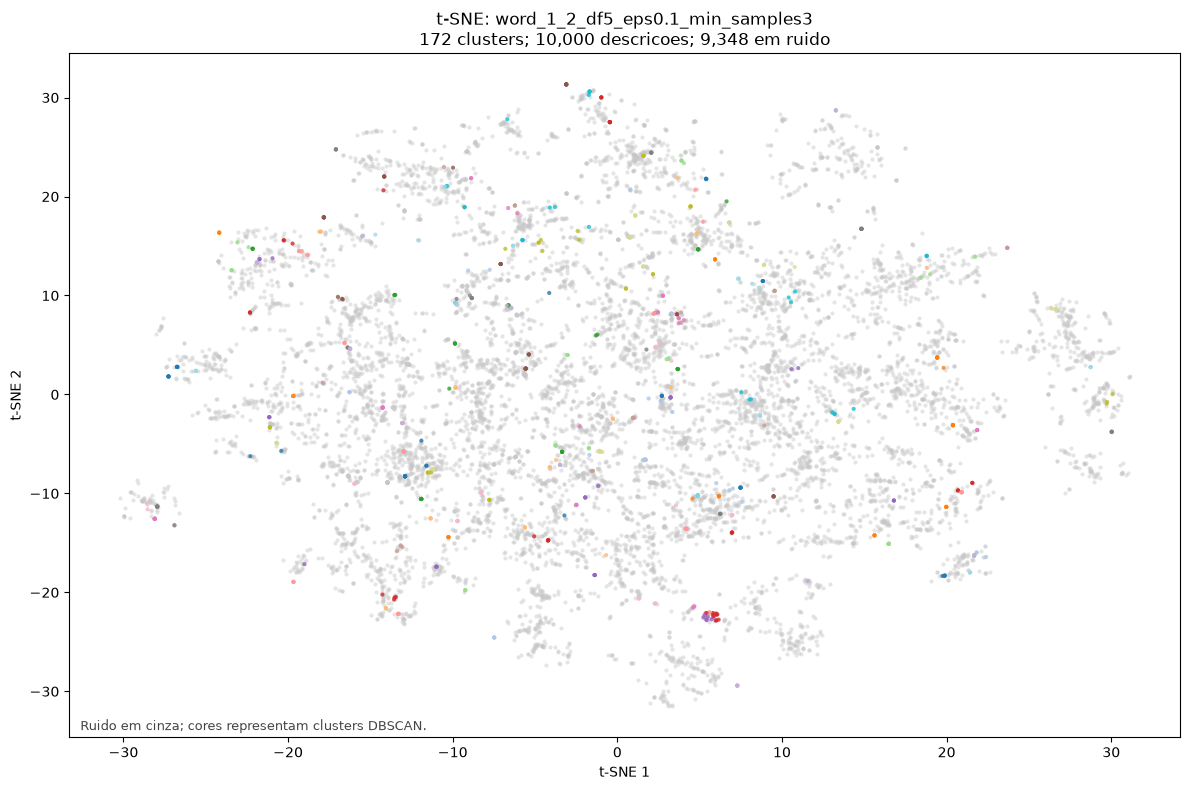

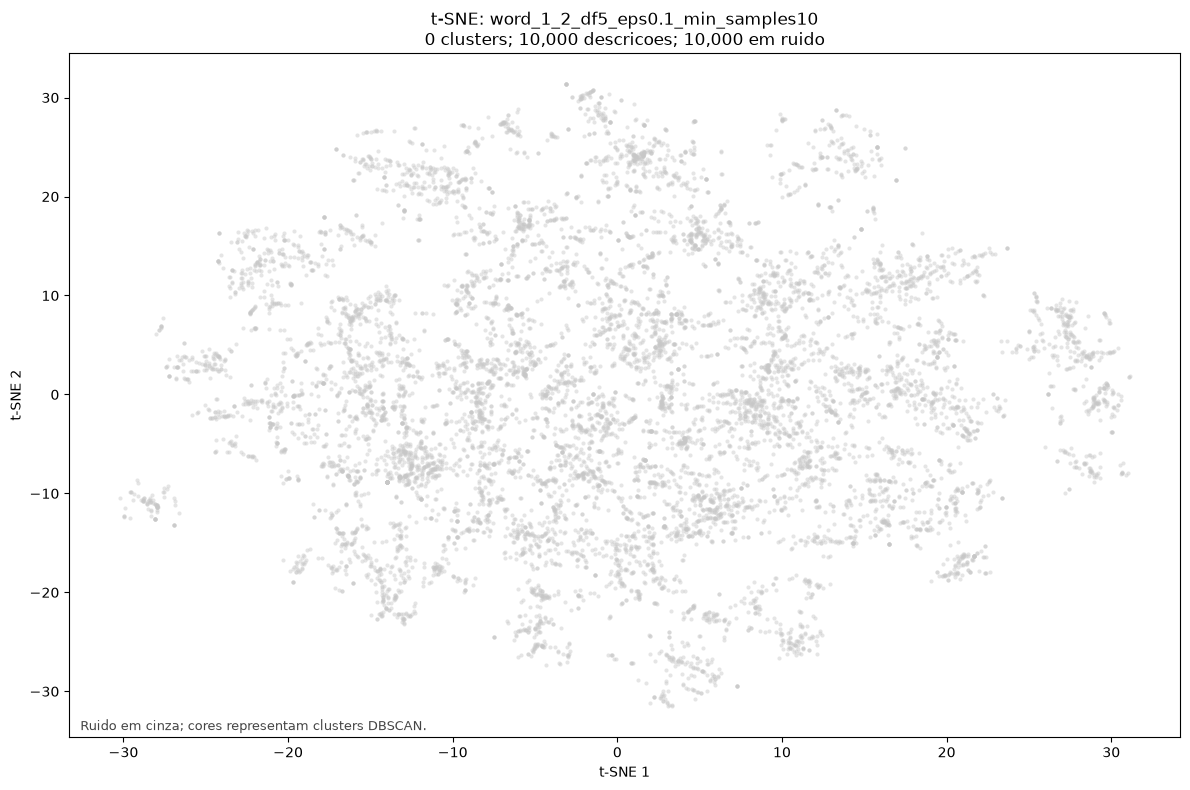

Vetorizando word_1_3_df5...
  Matriz: 10,000 descricoes x 2,846 features; 162 vetores zerados
  Aviso: 162 descricoes ficaram sem features nesta representacao.


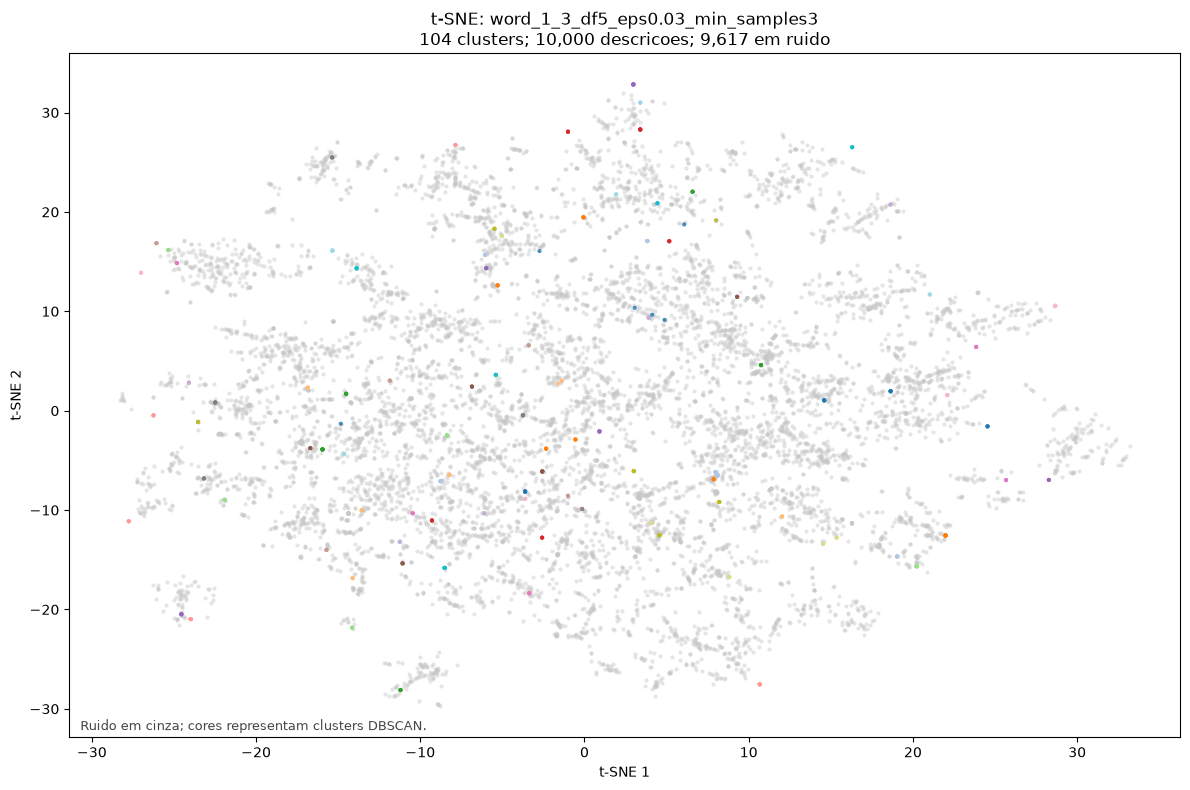

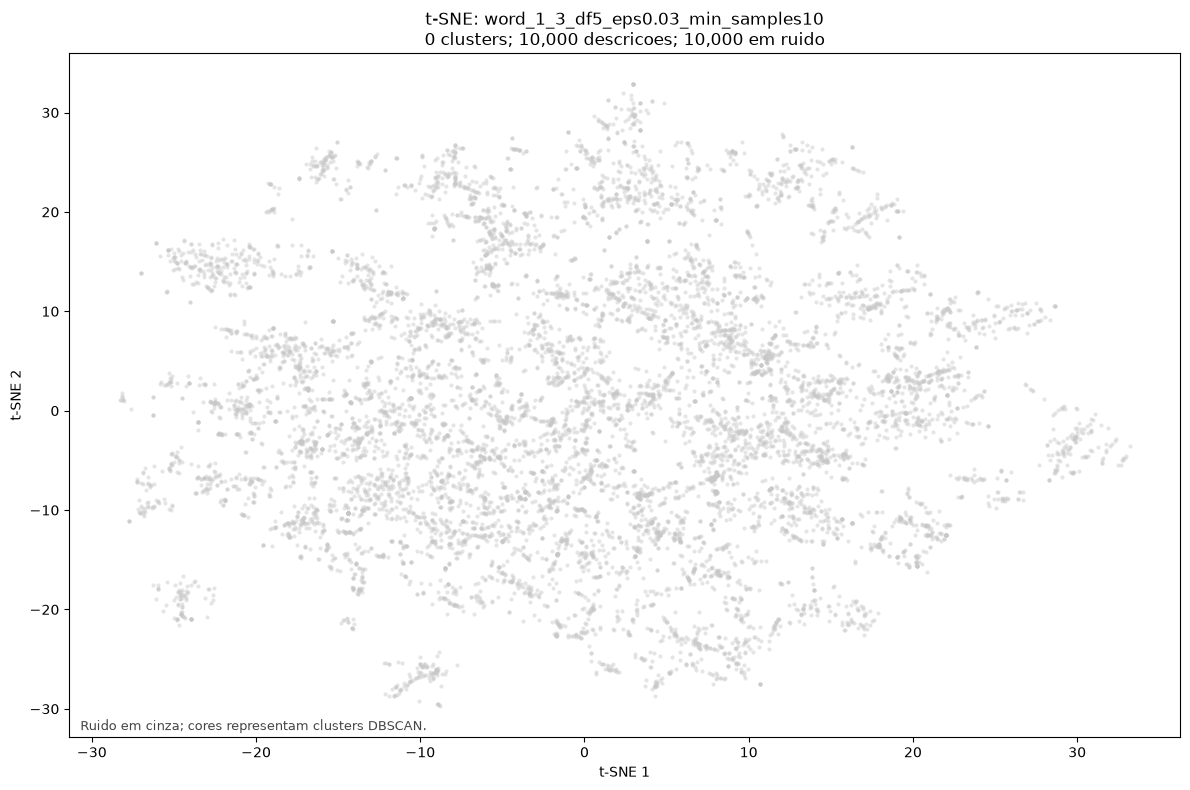

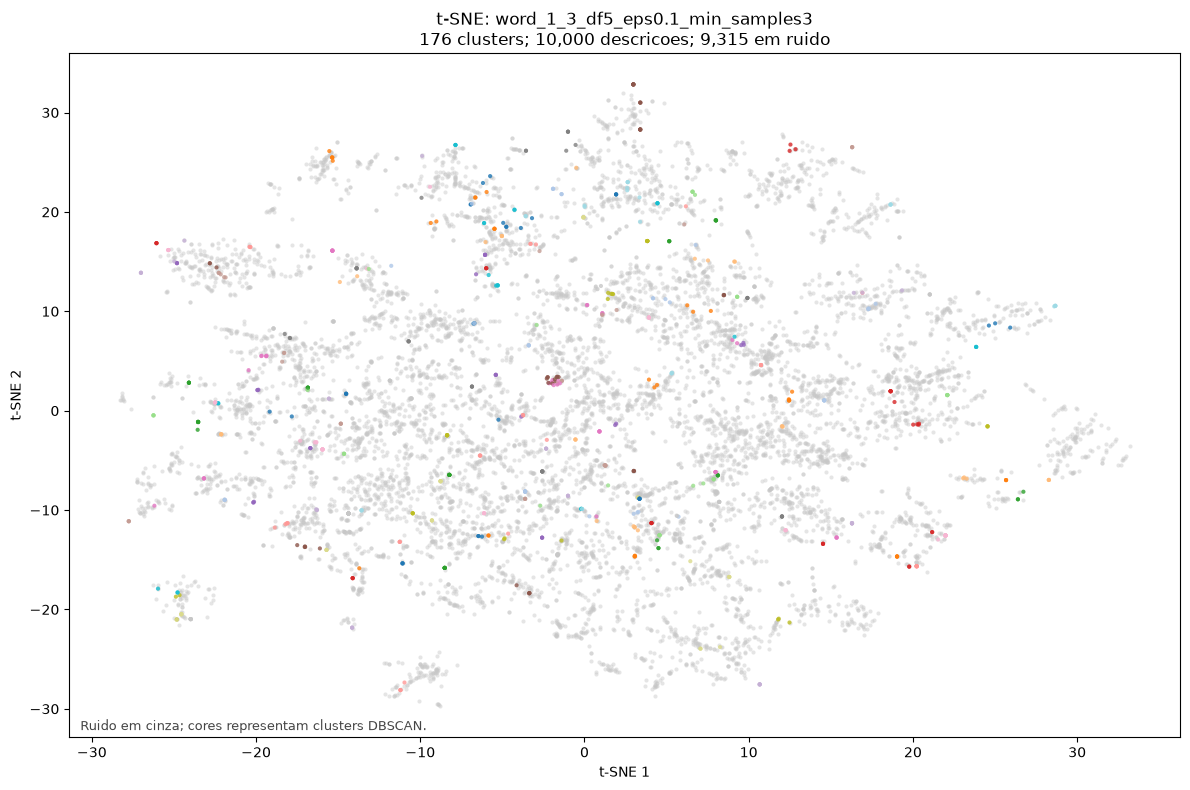

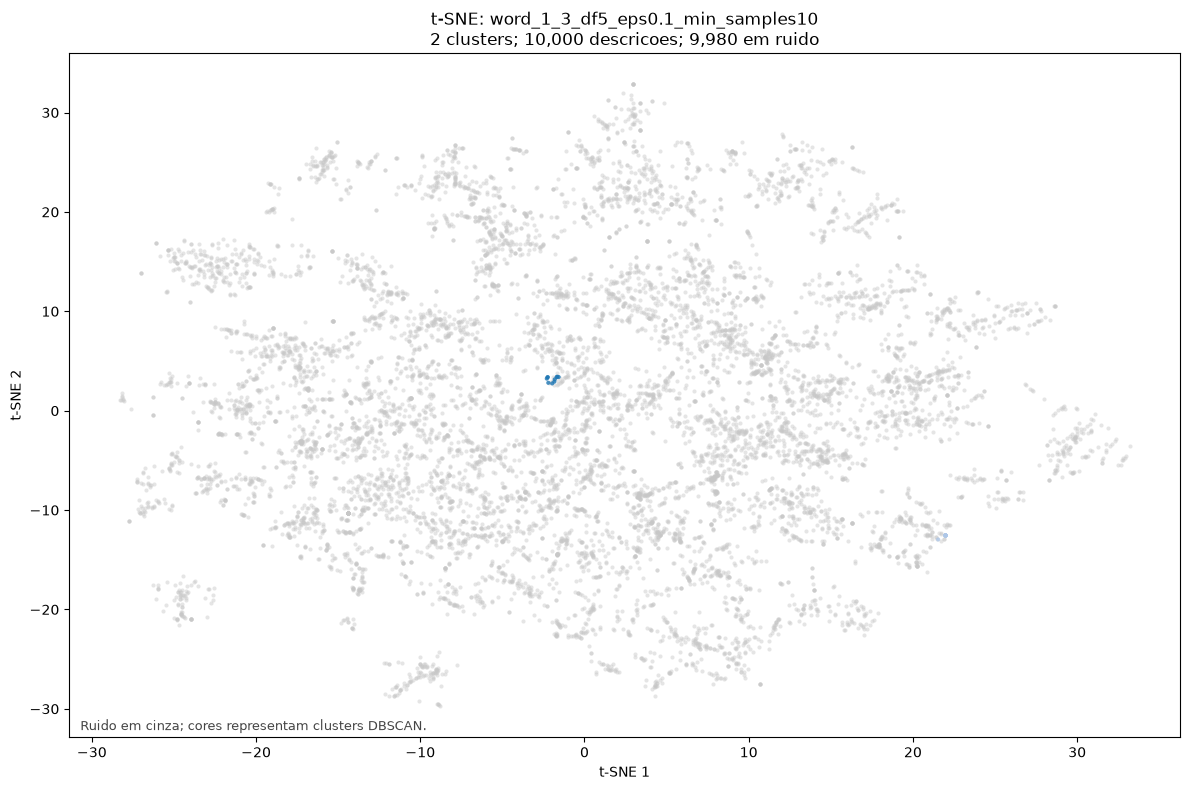

Vetorizando word_1_4_df5...
  Matriz: 10,000 descricoes x 2,897 features; 162 vetores zerados
  Aviso: 162 descricoes ficaram sem features nesta representacao.


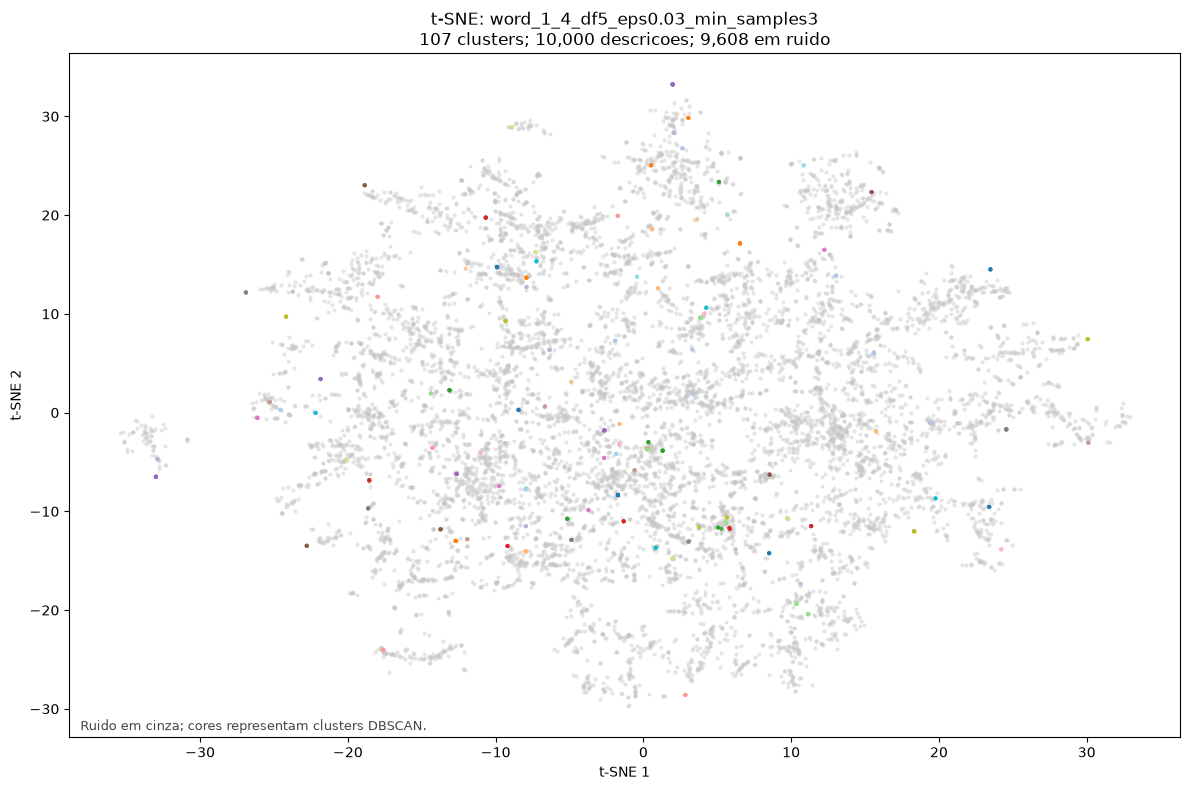

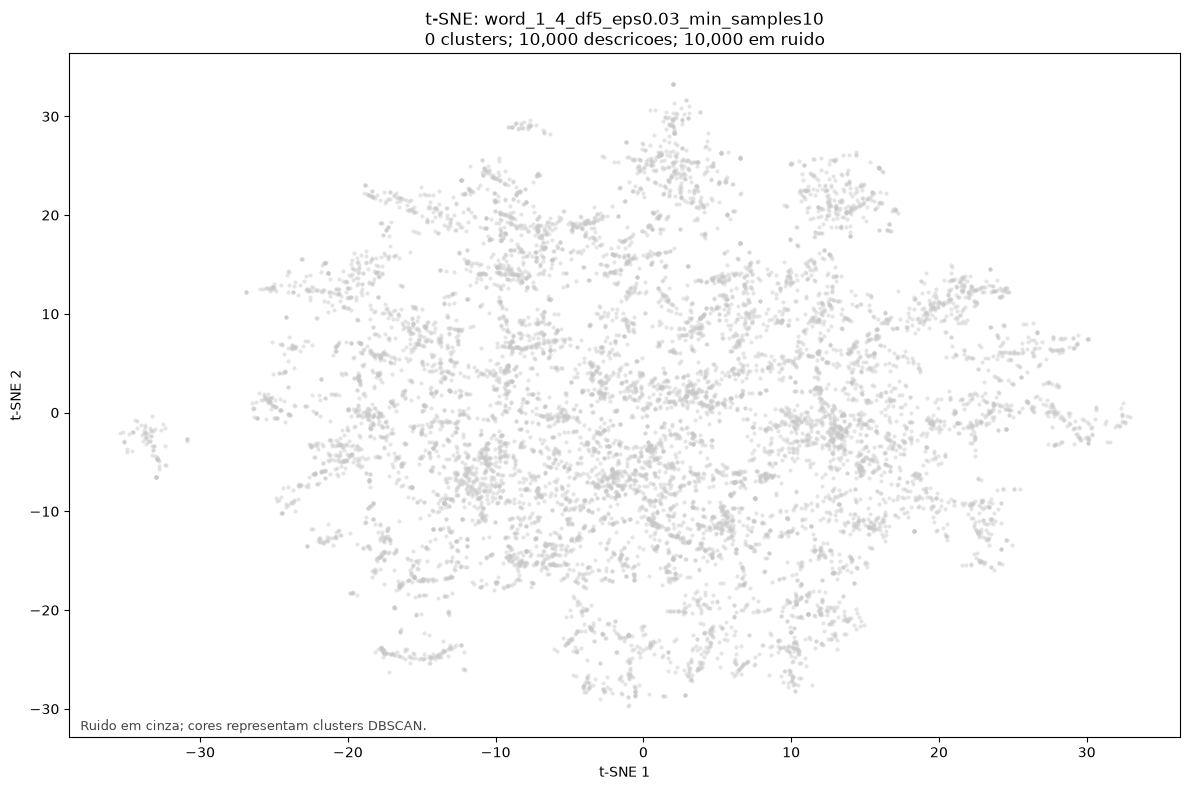

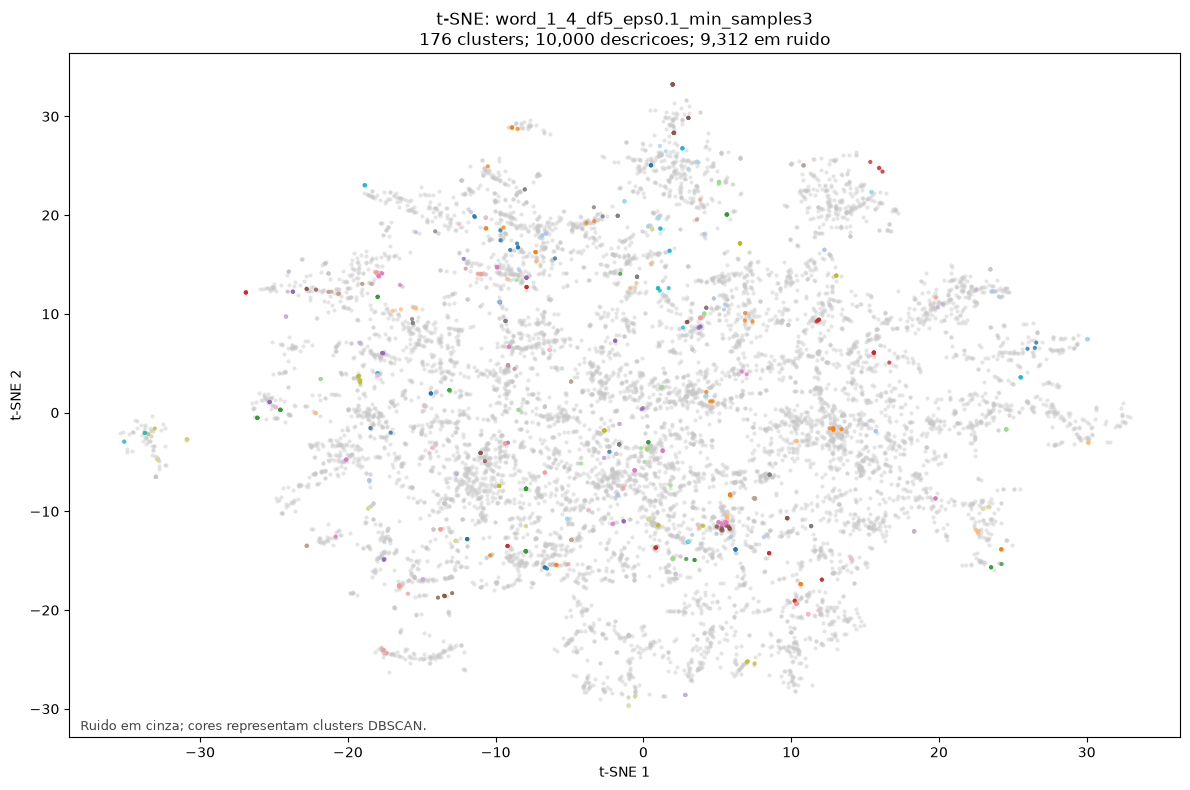

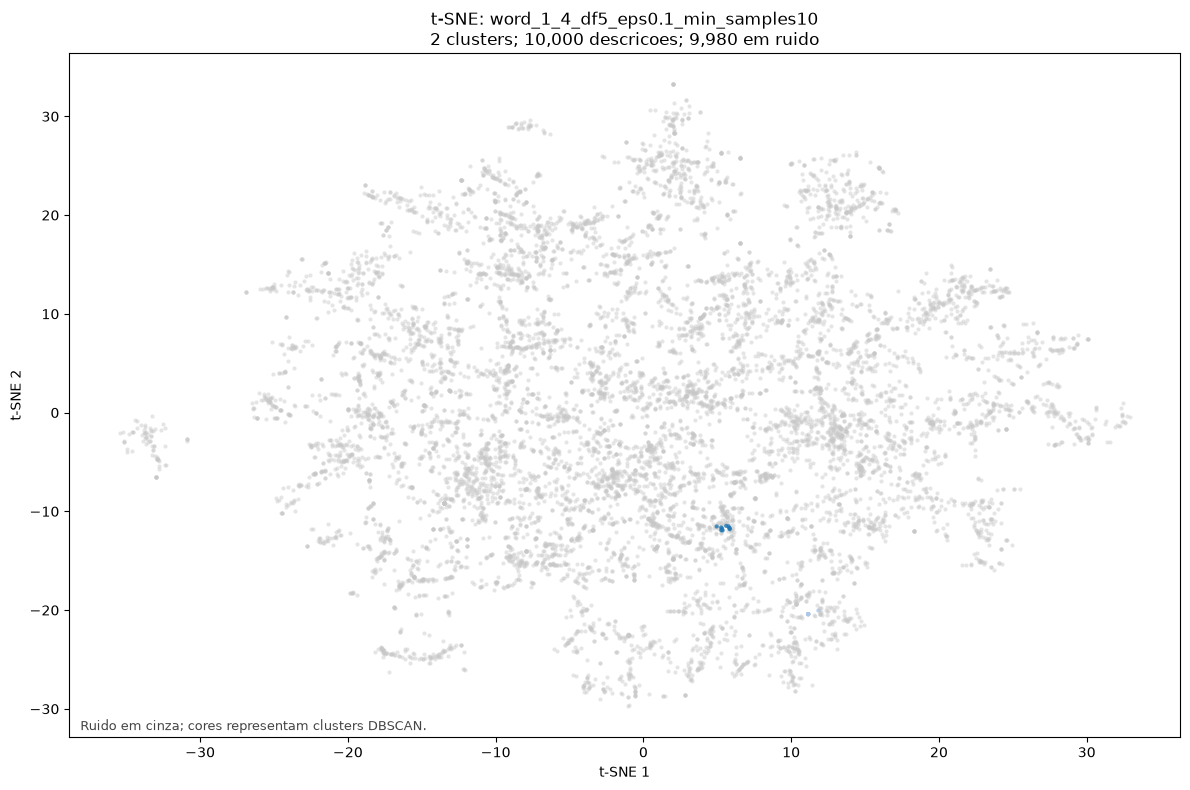

Vetorizando word_1_5_df5...
  Matriz: 10,000 descricoes x 2,919 features; 162 vetores zerados
  Aviso: 162 descricoes ficaram sem features nesta representacao.


In [ ]:
run_timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output_dir = OUTPUT_ROOT / f"{PERIOD_LABEL}_{run_timestamp}"
output_dir.mkdir(parents=True, exist_ok=False)
plots_dir = output_dir / "tsne_plots"
plots_dir.mkdir()
coordinates_dir = output_dir / "tsne_coordinates"
coordinates_dir.mkdir()
html_dir = output_dir / "interactive_html"
html_dir.mkdir()

texts = sampled_items["descricao_normalizada"].astype(str)
metric_records = []

for config in TFIDF_CONFIGS:
    config_name = config["name"]
    print(f"Vetorizando {config_name}...")
    vectorizer = TfidfVectorizer(
        analyzer=config["analyzer"],
        ngram_range=config["ngram_range"],
        min_df=config["min_df"],
        max_features=config["max_features"],
        sublinear_tf=True,
        norm="l2",
    )
    matrix = vectorizer.fit_transform(texts)
    zero_vector_count = int((matrix.getnnz(axis=1) == 0).sum())
    print(f"  Matriz: {matrix.shape[0]:,} descricoes x {matrix.shape[1]:,} features; {zero_vector_count:,} vetores zerados")
    if zero_vector_count:
        print(f"  Aviso: {zero_vector_count:,} descricoes ficaram sem features nesta representacao.")

    coordinates, svd_dimensions, effective_perplexity = project_with_tsne(
        matrix=matrix,
        perplexity=TSNE_PERPLEXITY,
        max_components=SVD_COMPONENTS,
        random_state=TSNE_RANDOM_STATE,
    )
    coordinate_frame = sampled_items.copy()
    coordinate_frame["tsne_1"] = coordinates[:, 0]
    coordinate_frame["tsne_2"] = coordinates[:, 1]
    coordinate_frame["tsne_3"] = coordinates[:, 2]
    coordinate_frame.to_csv(
        coordinates_dir / f"{config_name}_coordinates.csv",
        index=False,
        encoding="utf-8-sig",
    )

    html_cluster_options = []
    for eps in EPS_VALUES:
        for min_samples in MIN_SAMPLES_VALUES:
            model = DBSCAN(
                eps=eps,
                min_samples=min_samples,
                metric="cosine",
                algorithm="brute",
                n_jobs=DBSCAN_N_JOBS,
            )
            labels = model.fit_predict(matrix)
            cluster_ids, cluster_sizes = np.unique(labels[labels != -1], return_counts=True)
            noise_count = int(np.sum(labels == -1))
            run_id = f"{config_name}_eps{eps:g}_min_samples{min_samples}"
            plot_path = plots_dir / f"{run_id}.png"
            plot_clusters(coordinates, labels, run_id, plot_path)
            metric_records.append(
                {
                    "run_id": run_id,
                    "tfidf_config": config_name,
                    "analyzer": config["analyzer"],
                    "ngram_range": str(config["ngram_range"]),
                    "min_df": config["min_df"],
                    "max_features": config["max_features"],
                    "vocabulary_size": matrix.shape[1],
                    "zero_vector_count": zero_vector_count,
                    "zero_vector_fraction": zero_vector_count / len(texts),
                    "eps": eps,
                    "min_samples": min_samples,
                    "cluster_count": len(cluster_ids),
                    "noise_count": noise_count,
                    "noise_fraction": noise_count / len(labels),
                    "largest_cluster_size": int(cluster_sizes.max()) if len(cluster_sizes) else 0,
                    "svd_dimensions": svd_dimensions,
                    "tsne_perplexity": effective_perplexity,
                    "plot_path": str(plot_path),
                }
            )
            html_cluster_options.append({
                "name": f"eps={eps:g}, min_samples={min_samples}",
                "labels": labels.astype(int).tolist(),
                "cluster_count": int(len(cluster_ids)),
                "noise_count": noise_count,
            })

    html_path = html_dir / f"{config_name}_tsne_3d.html"
    save_interactive_tsne_html(
        coordinates=coordinates,
        items=sampled_items,
        cluster_options=html_cluster_options,
        title=f"t-SNE 3D — {config_name}",
        output_path=html_path,
    )

metrics = pd.DataFrame.from_records(metric_records).sort_values(
    ["tfidf_config", "eps", "min_samples"]
).reset_index(drop=True)
metrics_path = output_dir / "metrics.csv"
metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")

display(metrics)
print(f"Relatorios salvos em: {output_dir}")

## 5. Como interpretar

- Compare primeiro configuracoes que formaram mais de um cluster e nao deixaram quase todos os pontos como ruido ou em um grupo unico.
- `eps` controla a vizinhanca do DBSCAN. Valores maiores tendem a juntar pontos; valores menores podem aumentar o ruido. A escala muda entre representacoes TF-IDF.
- t-SNE mostra uma projecao 3D nos HTMLs interativos e uma vista 2D nos PNGs para inspecao. A distancia visual entre pontos nao substitui a distancia cosseno usada pelo DBSCAN; os clusters sao ajustados no espaco TF-IDF original.
- As cores identificam clusters apenas dentro de cada grafico e podem mudar de significado entre configuracoes.
- Leia os graficos junto com `metrics.csv` e com as descricoes originais. Agrupamentos visuais nao sao categorias validadas nem uma medida de acuracia.

As celulas acima gravam PNGs, HTMLs 3D interativos (um por representacao TF-IDF), coordenadas e metricas em uma pasta com timestamp. Cada execucao usa um novo diretorio para preservar os resultados anteriores.